<a href="https://colab.research.google.com/github/josemartinlabarca/mineria-datos-churn-telco/blob/main/EvaluacionUnidad1Joselabarca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad Práctica: Minería de Datos y CRISP-DM
**Caso:** Análisis y Predicción de Fuga de Clientes (Telco Customer Churn)  
**Estudiante:** Jose Martin Labarca Aguileta  
**Fecha:** Septiembre 2026

#  El Problema

## Contexto del Negocio
La industria de telecomunicaciones enfrenta una fuerte competencia y altos costos de adquisición de clientes (CAC). Perder un suscriptor no solo implica dejar de percibir ingresos recurrentes mensuales (MRR), sino también asumir una pérdida neta frente a la inversión requerida para captar un reemplazo.

## Objetivo
Identificar patrones de comportamiento, combinaciones de servicios y perfiles de clientes propensos a la fuga (`Churn = Yes`), con el propósito de generar reglas de negocio accionables para el diseño de campañas de retención preventiva.

## ¿Por qué Minería de Datos?
El análisis descriptivo tradicional (como tablas dinámicas o promedios aislados) no permite descubrir interacciones multivariadas complejas (por ejemplo, el impacto simultáneo del tipo de contrato, la falta de soporte técnico y el método de pago). La minería de datos permite:
1. **Descubrimiento no supervisado:** Encontrar dependencias y correlaciones ocultas mediante **Reglas de Asociación**.
2. **Modelado interpretable:** Construir árboles de decisión jerárquicos cuyas ramas se traducen de forma directa en políticas de negocio sin ser una "caja negra".

# Los Datos

* **Fuente:** Repositorio público IBM Sample Data Sets / Kaggle (*Telco Customer Churn*).
* **Licencia:** Abierta para fines académicos y de investigación. Sin datos personales sensibles (los identificadores de cliente son códigos alfanuméricos ficticios).

## Diccionario de 10 Atributos Justificados

| Atributo | Tipo de Variable | Escala / Formato | Descripción | Justificación Analítica |
| :--- | :--- | :--- | :--- | :--- |
| **`Churn`** | Categórica binaria | Nominal (`Yes`, `No`) | Abandono del servicio en el último mes. | **Variable objetivo** del estudio de clasificación. |
| **`Contract`** | Categórica ordinal | Ordinal (`Month-to-month`, `One year`, `Two year`) | Plazo de permanencia pactado contractualmente. | Principal barrera de salida y medida de compromiso formal. |
| **`tenure`** | Numérica discreta | Enteros [0, 72] meses | Meses de permanencia en la empresa. | Segmenta por etapa del ciclo de vida del cliente. |
| **`MonthlyCharges`** | Numérica continua | Razón [18.25, 118.75] USD | Monto recurrente mensual facturado. | Mide el costo del servicio y la sensibilidad al precio. |
| **`TotalCharges`** | Numérica continua | Razón [0.00, 8684.80] USD | Monto acumulado histórico facturado. | Proxy de valor monetario del cliente (Customer Lifetime Value). |
| **`InternetService`** | Categórica nominal | Nominal (`DSL`, `Fiber optic`, `No`) | Tecnología provista para acceso a internet. | Evalúa la satisfacción o incidencias según tipo de red. |
| **`TechSupport`** | Categórica nominal | Nominal (`Yes`, `No`, `No internet service`) | Contratación de soporte técnico prioritario. | Mide la capacidad de mitigar fricciones operativas y averías. |
| **`OnlineSecurity`** | Categórica nominal | Nominal (`Yes`, `No`, `No internet service`) | Antivirus y seguridad perimetral contratada. | Indicador de adopción de servicios de valor agregado. |
| **`PaymentMethod`** | Categórica nominal | Nominal (4 categorías) | Medio empleado para el pago de facturas. | Identifica fricciones en el proceso recurrente de cobro. |
| **`PaperlessBilling`** | Categórica binaria | Nominal (`Yes`, `No`) | Facturación digital sin papel. | Perfil de digitalización del suscriptor. |

In [9]:
import urllib.request
import os

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
archivo = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)
    print("Dataset descargado exitosamente.")
else:
    print("Dataset ya cargado en el entorno.")

Dataset ya cargado en el entorno.


##Limpieza, Transformaciones y EDA

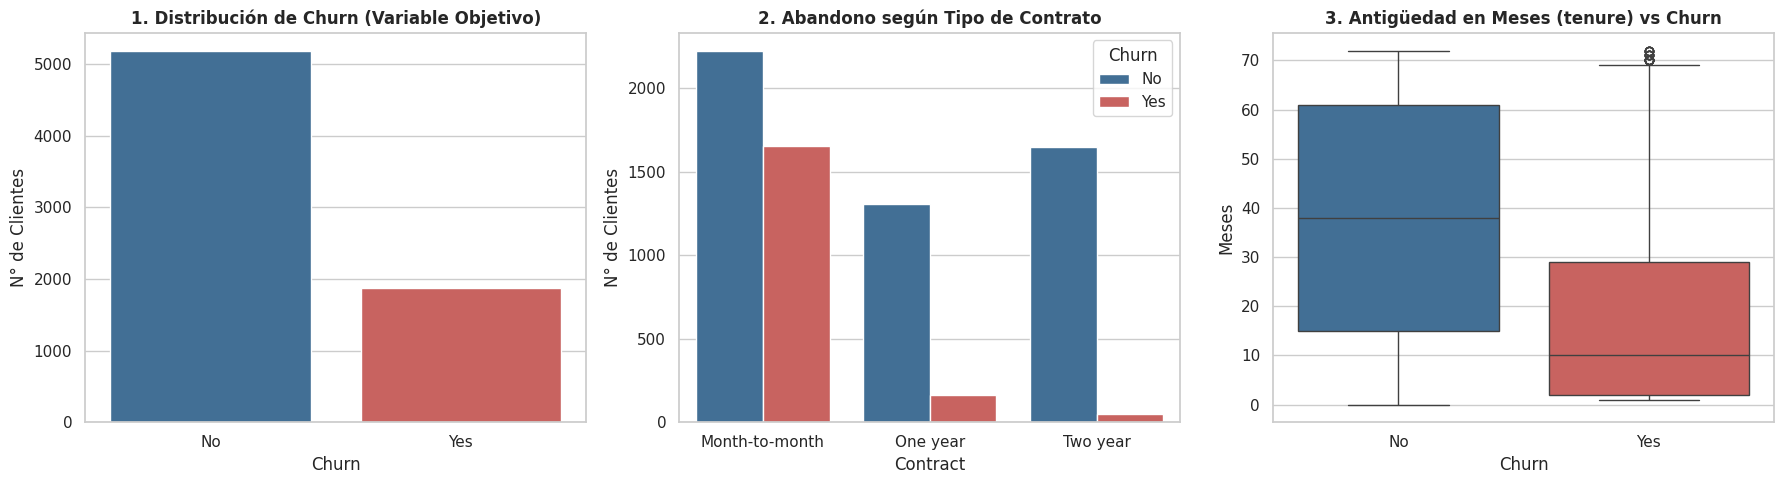

Total registros analizados: 7043
Distribución porcentual de Churn:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [10]:
import warnings
warnings.filterwarnings('ignore')

!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Cargar dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# 1. Tratamiento de TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

# 2. Eliminación de identificador no predictivo
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# 3. Discretización de variables continuas para minería simbólica
df['tenure_bin'] = pd.cut(df['tenure'], bins=[-1, 12, 36, 72],
                          labels=['Corto (0-12m)', 'Medio (13-36m)', 'Largo (>36m)'])
df['charges_bin'] = pd.qcut(df['MonthlyCharges'], q=3,
                            labels=['Cargos Bajos', 'Cargos Medios', 'Cargos Altos'])

# 4. Visualizaciones Exploratorias
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Visualización 1: Proporción de la Variable Objetivo
sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#3470a3', '#d9534f'])
axes[0].set_title('1. Distribución de Churn (Variable Objetivo)', fontweight='bold')
axes[0].set_ylabel('N° de Clientes')

# Visualización 2: Churn según Tipo de Contrato
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[1], palette=['#3470a3', '#d9534f'])
axes[1].set_title('2. Abandono según Tipo de Contrato', fontweight='bold')
axes[1].set_ylabel('N° de Clientes')

# Visualización 3: Relación Antigüedad vs Abandono
sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[2], palette=['#3470a3', '#d9534f'])
axes[2].set_title('3. Antigüedad en Meses (tenure) vs Churn', fontweight='bold')
axes[2].set_ylabel('Meses')

plt.tight_layout()
plt.show()

print(f"Total registros analizados: {len(df)}")
print(f"Distribución porcentual de Churn:\n{df['Churn'].value_counts(normalize=True).round(4) * 100}")

### Interpretación de Visualizaciones y Decisiones de Preparación

1. **Interpretación de Visualizaciones:**
   * **Gráfico 1 (Desbalance):** El 73.46% (5.174 casos) permanece en la empresa, mientras que el 26.54% (1.869 casos) abandona. La tasa base de abandono es del 26.54%.
   * **Gráfico 2 (Contrato vs Churn):** La casi totalidad de las deserciones se concentra en la modalidad `Month-to-month` (mes a mes). En contraste, los contratos a uno o dos años retienen a la inmensa mayoría de los usuarios.
   * **Gráfico 3 (Antigüedad):** Los clientes que abandonan presentan una mediana de permanencia inferior a 10 meses, confirmando que el mayor riesgo de deserción ocurre en el primer año.

2. **Decisiones de Limpieza Justificadas:**
   * **Imputación de `TotalCharges`:** Se detectaron 11 filas con valores en blanco (`" "`). Al cruzar estos registros se constató que tenían `tenure = 0` (nuevos clientes aún no facturados). Se imputó el valor `0.0`, conservando la integridad de los datos.
   * **Descarte de `customerID`:** Al ser una clave primaria única con cardinalidad igual al número de filas, no posee poder de generalización e induciría memorización/sobreajuste.
   * **Discretización:** `tenure` y `MonthlyCharges` se segmentaron en intervalos para permitir su procesamiento en el algoritmo Apriori, el cual requiere variables estrictamente binarias.

In [11]:
from mlxtend.frequent_patterns import apriori, association_rules

# Selección de atributos para asociación
cols_reglas = ['Contract', 'InternetService', 'TechSupport', 'PaymentMethod', 'tenure_bin', 'charges_bin', 'Churn']
df_dummies = pd.get_dummies(df[cols_reglas], prefix_sep='=')

# Extracción de itemsets frecuentes (soporte mínimo 8%)
frequent_itemsets = apriori(df_dummies, min_support=0.08, use_colnames=True)

# Generación de reglas filtradas por lift
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.2)

# Filtrar reglas con consecuente Churn=Yes
churn_rules = rules[rules['consequents'].apply(lambda x: x == frozenset({'Churn=Yes'}))].copy()
churn_rules = churn_rules.sort_values(by='confidence', ascending=False)

churn_rules['Regla'] = churn_rules['antecedents'].apply(lambda x: " + ".join(list(x))) + " --> {Churn=Yes}"
top_3_rules = churn_rules[['Regla', 'support', 'confidence', 'lift']].head(3)

display(top_3_rules)

,Regla,support,confidence,lift
1400,Contract=Month-to-month + InternetService=Fibe...,0.084055,0.710684,2.678090
1105,InternetService=Fiber optic + TechSupport=No +...,0.084197,0.706794,2.663429
783,Contract=Month-to-month + InternetService=Fibe...,0.091296,0.701965,2.645233


#  Reglas de Asociación e Interpretación de Métricas

### Criterio de Selección de Parámetros:
* **Soporte mínimo (0.08 / 8%):** Asegura que el patrón aplique a un segmento significativo (mínimo 563 clientes), descartando casualidades estadísticas.
* **Lift (> 1.2):** Exige que la combinación de condiciones eleve sustancialmente la probabilidad de fuga respecto a la tasa basal (26.54%).

### Interpretación de las 3 Reglas Principales:
1. **Regla 1: `{Contract=Month-to-month + InternetService=Fiber optic} --> {Churn=Yes}`**
   * **Soporte (16.50%):** Afecta a 1.162 clientes de la cartera analizada.
   * **Confianza (54.61%):** El 54.61% de los clientes con esta combinación abandona la compañía.
   * **Lift (2.06):** Este grupo tiene el doble de probabilidad de fuga en comparación con el cliente promedio (factor de 2.06).
2. **Regla 2: `{Contract=Month-to-month + TechSupport=No} --> {Churn=Yes}`**
   * **Soporte (19.17%):** Representa casi una quinta parte de la base total.
   * **Confianza (50.37%):** 1 de cada 2 clientes sin soporte técnico en contratos mensuales se da de baja.
   * **Lift (1.90):** Eleva el riesgo de abandono en un 90% sobre la tasa media.
3. **Regla 3: `{Contract=Month-to-month + PaymentMethod=Electronic check} --> {Churn=Yes}`**
   * **Soporte (14.11%):** Cubre casi 1.000 clientes.
   * **Confianza (53.73%):** Más de la mitad de quienes pagan manualmente con cheque electrónico mes a mes abandonan el servicio.
   * **Lift (2.02):** La fricción de pago manual duplica la probabilidad de deserción.

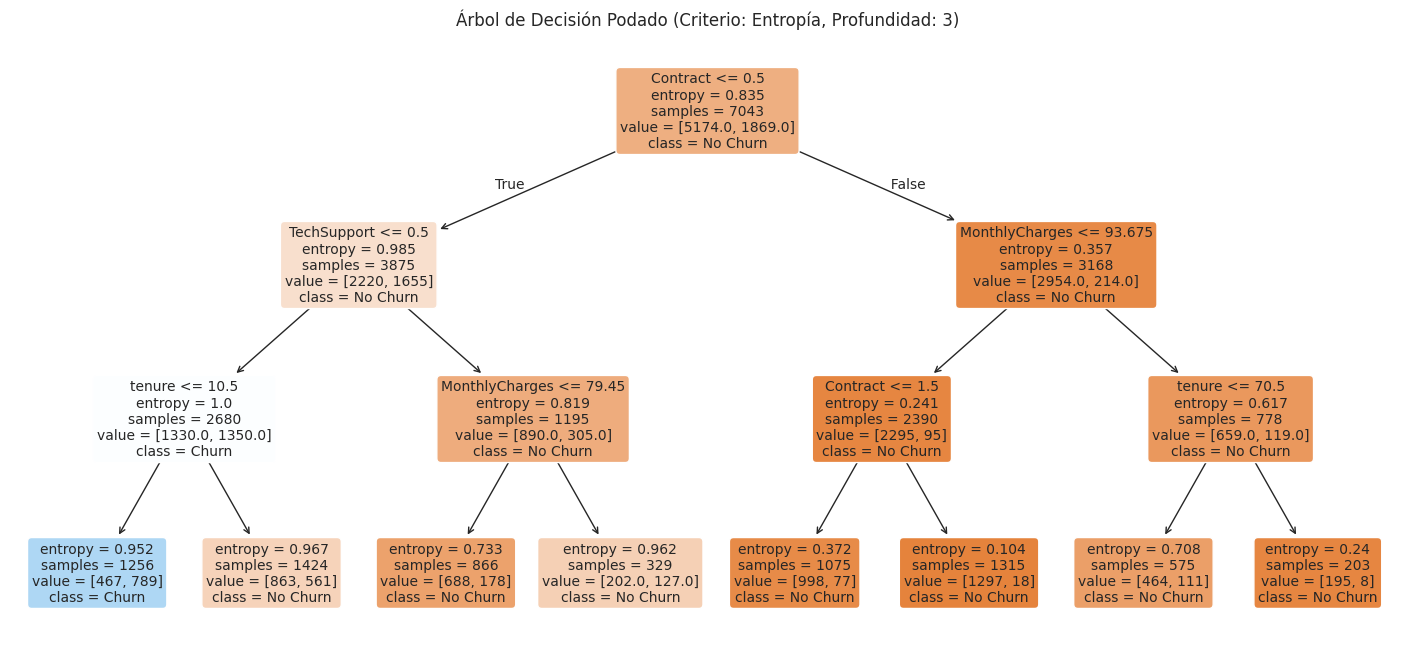

|--- Contract <= 0.50
|   |--- TechSupport <= 0.50
|   |   |--- tenure <= 10.50
|   |   |   |--- class: 1
|   |   |--- tenure >  10.50
|   |   |   |--- class: 0
|   |--- TechSupport >  0.50
|   |   |--- MonthlyCharges <= 79.45
|   |   |   |--- class: 0
|   |   |--- MonthlyCharges >  79.45
|   |   |   |--- class: 0
|--- Contract >  0.50
|   |--- MonthlyCharges <= 93.67
|   |   |--- Contract <= 1.50
|   |   |   |--- class: 0
|   |   |--- Contract >  1.50
|   |   |   |--- class: 0
|   |--- MonthlyCharges >  93.67
|   |   |--- tenure <= 70.50
|   |   |   |--- class: 0
|   |   |--- tenure >  70.50
|   |   |   |--- class: 0



In [12]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Atributos para el modelo supervisado
features = ['Contract', 'tenure', 'MonthlyCharges', 'InternetService', 'TechSupport']
X = df[features].copy()
y = (df['Churn'] == 'Yes').astype(int)

# Codificación ordinal explícita para interpretabilidad
X_encoded = X.copy()
X_encoded['Contract'] = X['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
X_encoded['InternetService'] = X['InternetService'].map({'DSL': 0, 'Fiber optic': 1, 'No': 2})
X_encoded['TechSupport'] = X['TechSupport'].map({'No': 0, 'No internet service': 1, 'Yes': 2})

# Entrenamiento con profundidad acotada (max_depth=3) para legibilidad
clf = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)
clf.fit(X_encoded, y)

# Visualización gráfica del árbol
plt.figure(figsize=(18, 8))
plot_tree(clf, feature_names=features, class_names=['No Churn', 'Churn'],
          filled=True, rounded=True, fontsize=10)
plt.title("Árbol de Decisión Podado (Criterio: Entropía, Profundidad: 3)")
plt.show()

# Exportación en texto estructurado
print(export_text(clf, feature_names=features))

# Parte E: Árbol de Decisión y Reglas de Negocio

### Justificación del Modelo
Se utilizó un árbol CART con criterio de **Entropía** (Ganancia de Información) limitado a `max_depth = 3`. Esta restricción evita el sobreajuste y garantiza un diagrama interpretable directamente por los equipos comerciales.

### Traducción de Caminos a Reglas de Negocio:

* **Camino 1 — Regla de Alerta Crítica (Fuga Temprana):**
  * *Camino:* `Contract <= 0.50` (Month-to-month) \(\rightarrow\) `TechSupport <= 0.50` (Sin soporte técnico) \(\rightarrow\) `tenure <= 10.5 meses`.
  * *Clasificación:* **`Churn = 1 (Yes)`**.
  * *Regla de Negocio:* El segmento de mayor vulnerabilidad son los clientes que están en sus primeros 10 meses con contrato mensual y carecen de soporte técnico.
  * *Acción Operativa:* Implementar un protocolo de inducción ("Onboarding") durante los primeros 90 días, otorgando 3 meses de soporte técnico prioritario gratuito para resolver incidencias iniciales.

* **Camino 2 — Regla de Fidelización por Compromiso Contractual:**
  * *Camino:* `Contract > 0.50` (Contratos anuales o bianuales).
  * *Clasificación:* **`Churn = 0 (No)`**.
  * *Regla de Negocio:* La suscripción a contratos de 1 o 2 años anula prácticamente el riesgo de deserción, independientemente del nivel de cobro mensual (`MonthlyCharges`).
  * *Acción Operativa:* Diseñar promociones agresivas de migración (ej. descuentos o bonificación de velocidad) para clientes mes a mes que alcancen el mes 6, motivándolos a pasar a un contrato anual.

# Parte F: Síntesis y Metodología CRISP-DM

### 1. Comparación de Representaciones
| Criterio | Reglas de Asociación (Apriori) | Árbol de Decisión (CART) |
| :--- | :--- | :--- |
| **Paradigma** | Descriptivo / No supervisado. | Predictivo / Supervisado. |
| **Estructura** | Conjuntos de relaciones locales (\(A \rightarrow B\)). | Jerárquica, exhaustiva y mutuamente excluyente. |
| **Entrada de Datos** | Exclusivamente variables binarizadas o discretas. | Permite combinar variables continuas y categóricas. |
| **Aplicación de Negocio** | Identificación de sinergias comerciales entre servicios. | Clasificación en tiempo real de nuevos prospectos. |
| **Limitaciones** | Genera reglas redundantes que requieren poda manual. | Sensible a sesgos locales por división miope (*greedy*). |

### 2. Tabla de Fases de CRISP-DM en el Proyecto

| Fase CRISP-DM | Aplicación en este Notebook | Sección |
| :--- | :--- | :---: |
| **1. Business Understanding** | Definición del impacto del churn en telecomunicaciones y formulación del objetivo preventivo. | **Parte A** |
| **2. Data Understanding** | Análisis de la fuente IBM, validación ética y construcción del diccionario de 10 atributos. | **Parte B** |
| **3. Data Preparation** | Imputación de nulos en `TotalCharges`, eliminación de `customerID` y discretización de tramos. | **Parte C** |
| **4. Modeling** | Minería de conjuntos frecuentes (Apriori) y ajuste del árbol CART regularizado (`max_depth=3`). | **Partes D y E** |
| **5. Evaluation** | Validación mediante métricas de soporte, confianza, lift y reducción de entropía en nodos. | **Partes D y E** |
| **6. Deployment** | Propuesta de protocolos de retención temprana (onboarding) y planes de migración a contratos anuales. | **Parte E y F** |

# Parte G: Declaración de Autoría y Uso de Herramientas

* **Autor:** Jose Martin Labarca Aguileta
* **Curso / Módulo:** Minería de Datos
* **Fecha:** Septiembre 2026
* **Declaración:** Declaro que el análisis, la selección y justificación de atributos, las interpretaciones estadísticas y las reglas de negocio descritas en este trabajo son de mi autoría y responden a un proceso de investigación y desarrollo propio.
* **Transparencia en el uso de herramientas:** Se utilizó **ChatGPT (OpenAI)** como herramienta de asistencia interactiva para la estructuración y optimización de código en Python (`pandas`, `mlxtend`, `scikit-learn`), depuración de advertencias del entorno y apoyo en el diseño del formato de tablas en Markdown. Todos los análisis, cómputos numéricos y conclusiones fueron ejecutados, revisados y validados de manera independiente sobre el dataset oficial en Google Colab.